Figure saved to ../plots/FigureChattering_A.pdf


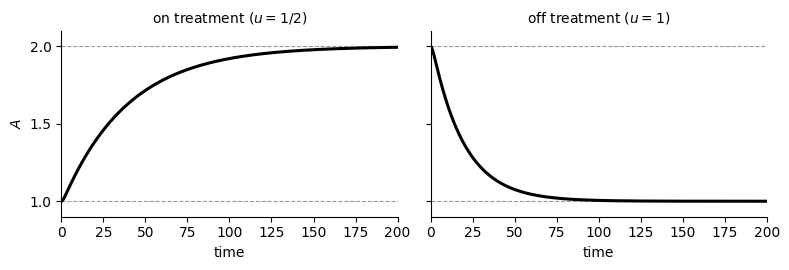

In [1]:
"""Low-q regime of the AB integral-feedback model: why A lives in (1, 2).

    dA/dt = q * (1 - B)          slow integral feedback (q << 1)
    dB/dt = u * A - B            fast relaxation of B to its QSS B = u*A

u = 1 is off-treatment, u = u_min = 1/2 is the maximal dose. Under a constant
control B adapts back to 1 and A settles at A* = 1/u, so
    off  (u = 1):    A -> 1
    on   (u = 1/2):  A -> 2.
Starting from A(0) = 1, A can never leave [1, 2]: on-treatment pushes it up
towards 2, off-treatment pulls it down towards 1, and any chattering mix of the
two keeps it in between.
"""
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

PLOTS_DIR = Path("../plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a matplotlib figure to PLOTS_DIR as a PDF."""
    if not name.lower().endswith(".pdf"):
        name = f"{name}.pdf"
    save_path = PLOTS_DIR / name
    fig.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Figure saved to {save_path}")


# --- palette (shared with Figure 1) ---------------------------------------
FEEDBACK = "black"        # A
REGULATED = "#e5a024"     # B
REF = "#9A9A9A"           # reference lines
plt.rcParams.update({"pdf.fonttype": 42})

# --- parameters -----------------------------------------------------------
q = 0.05                  # low q: B is fast compared to A
u_on, u_off = 0.5, 1.0    # maximal dose / no treatment
T = 200.0                 # long enough for A to settle (slow rate ~ q*u)


def rhs(t, y, u):
    A, B = y
    return [q * (1 - B), u * A - B]


t = np.linspace(0, T, 3000)
# on-treatment from the untreated steady state (1, 1)
A_on, B_on = solve_ivp(rhs, [0, T], [1.0, 1.0], args=(u_on,),
                       t_eval=t, rtol=1e-8, atol=1e-10).y
# off-treatment from the on-treatment steady state (2, 1)
A_off, B_off = solve_ivp(rhs, [0, T], [1 / u_on, 1.0], args=(u_off,),
                         t_eval=t, rtol=1e-8, atol=1e-10).y

fig, (ax_on, ax_off) = plt.subplots(1, 2, figsize=(8, 2.8), sharey=True)
panels = [(ax_on, A_on, "on treatment ($u=1/2$)"),
          (ax_off, A_off, "off treatment ($u=1$)")]
for ax, A, title in panels:
    for level in (1.0, 2.0):      # the two equilibria of A
        ax.axhline(level, color=REF, lw=0.8, ls="--", zorder=1)
    ax.plot(t, A, color=FEEDBACK, lw=2.2, zorder=2)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, T)
    ax.set_xlabel("time")
    ax.spines[["top", "right"]].set_visible(False)
ax_on.set_ylim(0.9, 2.1)
ax_on.set_yticks([1, 1.5, 2])
ax_on.set_ylabel("$A$")
fig.tight_layout()
save_fig(fig, "FigureChattering_A")

Figure saved to ../plots/FigureChattering_B.pdf


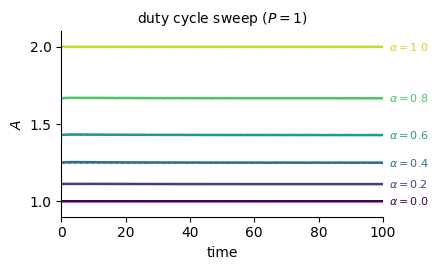

In [2]:
# --- any A in [1, 2] can be held by fast switching ------------------------
# Switching on/off with duty cycle alpha (fraction of each period spent on)
# averages the two vector fields. With B at its QSS, constant A requires
#     <u> A = 1  ->  (1 - alpha/2) A = 1  ->  A* = 2 / (2 - alpha),
# which sweeps [1, 2] as alpha goes from 0 to 1. A short switching period P
# keeps the ripple small: A drifts by ~q*P during each phase.


def simulate_pwm(alpha, P, A0, T, n_per_phase=40):
    """Integrate the AB model under on/off switching, one phase at a time."""
    t_out, A_out = [], []
    y, t0 = [A0, 1.0], 0.0            # start on, with B at its period average
    while t0 < T:
        for u, dur in ((u_on, alpha * P), (u_off, (1 - alpha) * P)):
            if dur <= 0:
                continue
            ts = np.linspace(t0, t0 + dur, n_per_phase)
            sol = solve_ivp(rhs, [t0, t0 + dur], y, args=(u,), t_eval=ts,
                            rtol=1e-8, atol=1e-10)
            t_out.append(sol.t)
            A_out.append(sol.y[0])
            y, t0 = sol.y[:, -1], t0 + dur
    return np.concatenate(t_out), np.concatenate(A_out)


T_pwm = 100.0
P_fast = 1.0                                 # switching period
alphas = np.linspace(0, 1, 6)                # duty cycles 0, 0.2, ..., 1
cmap = plt.cm.viridis

fig, ax = plt.subplots(figsize=(4.5, 2.8))
# one duty cycle per target: A stays at 2 / (2 - alpha)
for k, alpha in enumerate(alphas):
    A_star = 2 / (2 - alpha)
    t_p, A_p = simulate_pwm(alpha, P_fast, A_star, T_pwm)
    color = cmap(0.9 * k / (len(alphas) - 1))
    ax.axhline(A_star, color=REF, lw=0.8, ls="--", zorder=1)
    ax.plot(t_p, A_p, color=color, lw=1.8, zorder=2)
    ax.text(T_pwm * 1.02, A_star, rf"$\alpha={alpha:.1f}$",
            color=color, va="center", fontsize=8)
ax.set_xlim(0, T_pwm)
ax.set_ylim(0.9, 2.1)
ax.set_yticks([1, 1.5, 2])
ax.set_xlabel("time")
ax.set_ylabel("$A$")
ax.set_title(f"duty cycle sweep ($P={P_fast:g}$)", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "FigureChattering_B")